# Exploratory Data Analysis: WDI and Olympic Performance

**Project:** Predicting Olympic Success from National Economic Conditions (IST 707)


## Part 1: Initial Exploratory Data Analysis


In [24]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)

DATA_PATH = (
    "https://raw.githubusercontent.com/"
    "ahmadmashhood01/IST.707-PROJECT/main/"
    "Dataset/olympic_economics.csv"
)

pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


## 1. Load the already merged dataset


In [25]:
data = pd.read_csv(DATA_PATH)
original_shape = data.shape
print("Original shape:", original_shape)
display(data.head(3))


Original shape: (13584, 74)


,ID,Country,wdi_code,year,Gross capital formation (% of GDP),Gross fixed capital formation (% of GDP),Multidimensional poverty headcount ratio (World Bank) (% of population),"Labor force participation rate, male (% of male population ages 15+) (modeled ILO estimate)","Labor force participation rate, female (% of female population ages 15+) (modeled ILO estimate)",GNI per capita (constant 2015 US$),Price level index (GDP),"Inflation, consumer prices (annual %)","Inflation, GDP deflator (annual %)",Imports of goods and services (% of GDP),Exports of goods and services (% of GDP),"Official exchange rate (LCU per US$, period average)",GDP growth (annual %),GDP per capita (current US$),GDP (current US$),"Droughts, floods, extreme temperatures (% of population, average 1990-2009)",General government final consumption expenditure (% of GDP),Urban population (% of total population),Domestic credit to private sector (% of GDP),Account ownership at a financial institution or with a mobile-money-service provider (% of population ages 15+),"Foreign direct investment, net inflows (% of GDP)","Foreign direct investment, net outflows (% of GDP)","Intentional homicides (per 100,000 people)",Control of Corruption - Governance estimate (approx. -2.5 to +2.5),Control of Corruption - Governance score (0-100),"CPIA transparency, accountability, and corruption in the public sector rating (1=low to 6=high)","School enrollment, secondary (% gross)","School enrollment, primary (% gross)","School enrollment, tertiary (% gross)","Government expenditure on education, total (% of GDP)","Educational attainment, at least completed upper secondary, population 25+, total (%) (cumulative)",Current health expenditure (% of GDP),Gini index,"Children in employment, total (% of children ages 7-14)","Employment to population ratio, 15+, total (%) (modeled ILO estimate)","Agriculture, forestry, and fishing, value added (% of GDP)",Import value index (2015 = 100),Export value index (2015 = 100),"Population, total",Population growth (annual %),Population density (people per sq. km of land area),"Life expectancy at birth, total (years)","Central government debt, total (% of GDP)",Research and development expenditure (% of GDP),Individuals using the Internet (% of population),Tax revenue (% of GDP),CPIA trade rating (1=low to 6=high),CPIA social protection rating (1=low to 6=high),CPIA property rights and rule-based governance rating (1=low to 6=high),CPIA policies for social inclusion/equity cluster average (1=low to 6=high),CPIA gender equality rating (1=low to 6=high),CPIA business regulatory environment rating (1=low to 6=high),People using at least basic drinking water services (% of population),Prevalence of severe food insecurity in the population (%),"Mortality rate, under-5 (per 1,000 live births)","Fertility rate, total (births per woman)",CPIA equity of public resource use rating (1=low to 6=high),CPIA building human resources rating (1=low to 6=high),"International tourism, receipts (% of total exports)","International tourism, number of arrivals",Military expenditure (% of GDP),Access to electricity (% of population),country,olympic_code,athlete_count,event_entries,gold,silver,bronze,total
0,ABW60,Aruba,ABW,1960,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,59.0237,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"54,922.0000",NaN,NaN,64.0490,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.5670,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ABW61,Aruba,ABW,1961,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,59.0728,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"55,578.0000",1.1873,308.7667,64.2150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.4220,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ABW62,Aruba,ABW,1962,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,59.2123,NaN,NaN,NaN,NaN,NaN,NaN,NaN

## 2. WDI structure, coverage, and cleaning

Coverage is calculated across **all rows in the merged file**, before choosing any analysis window. Drop only WDI indicators with less than 10% nonmissing data; retain exactly 10%. Identifiers, Olympic fields, zero values, and all rows—including historical countries—are preserved.


In [ ]:
ID_COLS = ["ID", "Country", "wdi_code", "year", "country", "olympic_code",
           "athlete_count", "event_entries", "gold", "silver", "bronze", "total"]
required = {"wdi_code", "year", "country", "olympic_code", "athlete_count",
            "event_entries", "gold", "silver", "bronze", "total"}
missing = required.difference(data.columns)
if missing:
    raise ValueError(f"Missing required merged-dataset columns: {sorted(missing)}")
WDI_COLS = [c for c in data.columns if c not in ID_COLS]

data[WDI_COLS] = data[WDI_COLS].replace(r"^\s*$|^\s*\.\.\s*$", np.nan, regex=True)
coverage = data[WDI_COLS].notna().mean()
DROP_COLS = coverage[coverage < 0.10].index.tolist()
ECON_COLS = coverage[coverage >= 0.10].index.tolist()


In [ ]:
coverage_report = pd.DataFrame({"pct_filled": coverage * 100,
                                "pct_missing": (1 - coverage) * 100,

                                "action": np.where(coverage < 0.10, "drop", "keep")})


In [ ]:
data = data.drop(columns=DROP_COLS)
assert len(data) == original_shape[0]
print("WDI indicators before / dropped / retained:", len(WDI_COLS), len(DROP_COLS), len(ECON_COLS))
print("Cleaned shape:", data.shape)
print("Years:", data["year"].min(), "to", data["year"].max())
print("WDI codes:", data["wdi_code"].nunique())
display(coverage_report.sort_values("pct_filled"))
print("Dropped WDI indicators:")
for col in DROP_COLS:
    print(f"{col}: {coverage[col] * 100:.2f}% filled")


In [ ]:
miss = (data[ECON_COLS].isna().mean() * 100).sort_values(ascending=False)


In [26]:
olympics = data[data["olympic_code"].notna()].copy()
panel = olympics[olympics["year"].between(1990, 2016)].copy()


WDI indicators before / dropped / retained: 62 8 54
Cleaned shape: (13584, 66)
Years: 1960 to 2025
WDI codes: 205


,pct_filled,pct_missing,action
Price level index (GDP),0.0000,100.0000,drop
Control of Corruption - Governance estimate (approx. -2.5 to +2.5),0.0000,100.0000,drop
Control of Corruption - Governance score (0-100),0.0000,100.0000,drop
"Droughts, floods, extreme temperatures (% of population, average 1990-2009)",1.2367,98.7633,drop
"Children in employment, total (% of children ages 7-14)",2.0686,97.9314,drop
...,...,...,...
"Life expectancy at birth, total (years)",97.8431,2.1569,keep
"Fertility rate, total (births per woman)",97.8578,2.1422,keep
Population growth (annual %),97.8578,2.1422,keep
"Population, total",99.3816,0.6184,keep


Dropped WDI indicators:
Multidimensional poverty headcount ratio (World Bank) (% of population): 7.49% filled
Price level index (GDP): 0.00% filled
Droughts, floods, extreme temperatures (% of population, average 1990-2009): 1.24% filled
Account ownership at a financial institution or with a mobile-money-service provider (% of population ages 15+): 5.19% filled
Control of Corruption - Governance estimate (approx. -2.5 to +2.5): 0.00% filled
Control of Corruption - Governance score (0-100): 0.00% filled
Children in employment, total (% of children ages 7-14): 2.07% filled
Prevalence of severe food insecurity in the population (%): 8.33% filled


## 3. WDI missingness (cleaning guide)


In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
miss.head(25).plot.barh(ax=ax, color="coral")
ax.set_xlabel("% missing")
ax.set_title("Top 25 WDI indicators by missingness")
plt.tight_layout()
plt.show()


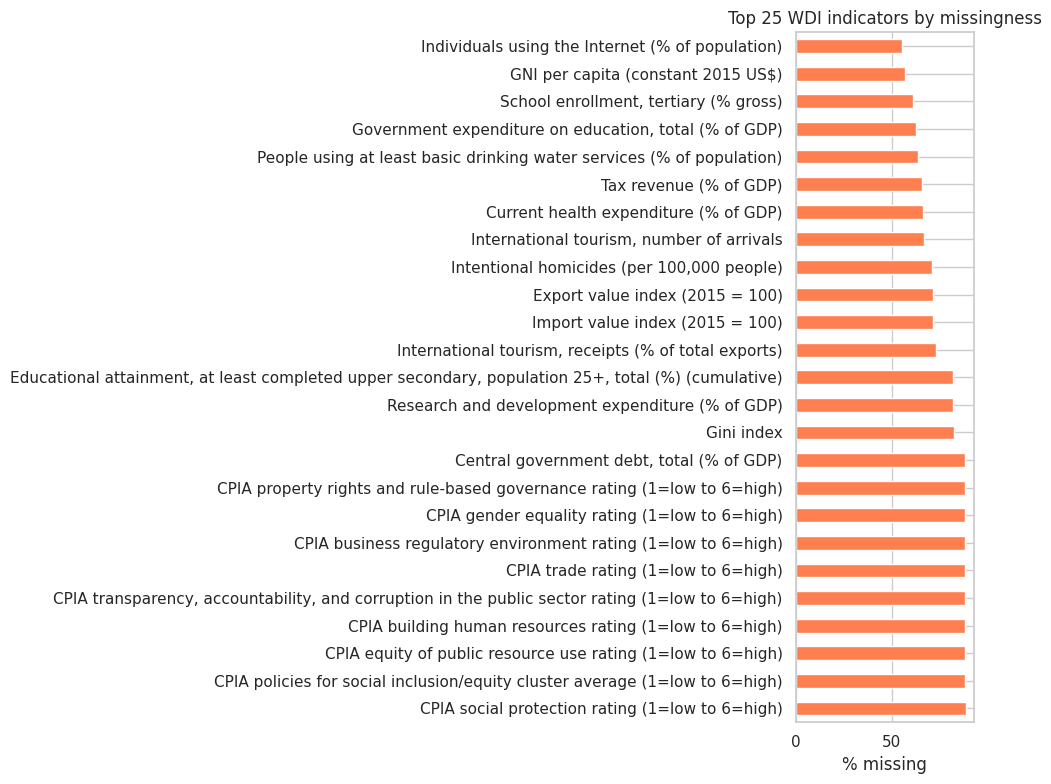

,avg_pct_missing_across_indicators
wdi_code,
PRK,81.5376
VGB,80.1347
ASM,80.0786
CUW,78.9001
SSD,76.4029
CYM,76.0943
GUM,75.7856
LIE,75.6173
VIR,75.5612


In [27]:
country_miss = (
    data.groupby("wdi_code")[ECON_COLS]
    .apply(lambda df: df.isna().mean().mean() * 100)
    .sort_values(ascending=False)
)
display(country_miss.head(15).to_frame("avg_pct_missing_across_indicators"))


## 4. WDI distributions (log scale for GDP / population)


In [28]:
print("Full merged rows:", len(data))
print("Olympic observations:", len(olympics))
print("Olympic observations with no retained WDI data:", olympics[ECON_COLS].isna().all(axis=1).sum())
print("Olympic observations without WDI code:", olympics["wdi_code"].isna().sum())
print("1990-2016 Olympic panel:", len(panel))
for code, yr in [("USA", 2016), ("CHN", 2016), ("KEN", 2016), ("AFG", 2016)]:
    r = olympics[(olympics["olympic_code"] == code) & (olympics["year"] == yr)]
    if len(r):
        row = r.iloc[0]
        print(code, yr, "athletes", row["athlete_count"], "medals", row["total"],
              "gdp_pc", row.get("GDP per capita (current US$)", np.nan))


Full merged rows: 13584
Olympic observations: 2715
Olympic observations with no retained WDI data: 54
Olympic observations without WDI code: 54
1990-2016 Olympic panel: 1824
USA 2016 athletes 555.0 medals 121.0 gdp_pc 57976.6282
CHN 2016 athletes 392.0 medals 70.0 gdp_pc 8254.868593
KEN 2016 athletes 79.0 medals 13.0 gdp_pc 1554.126103
AFG 2016 athletes 3.0 medals 0.0 gdp_pc 522.0822156


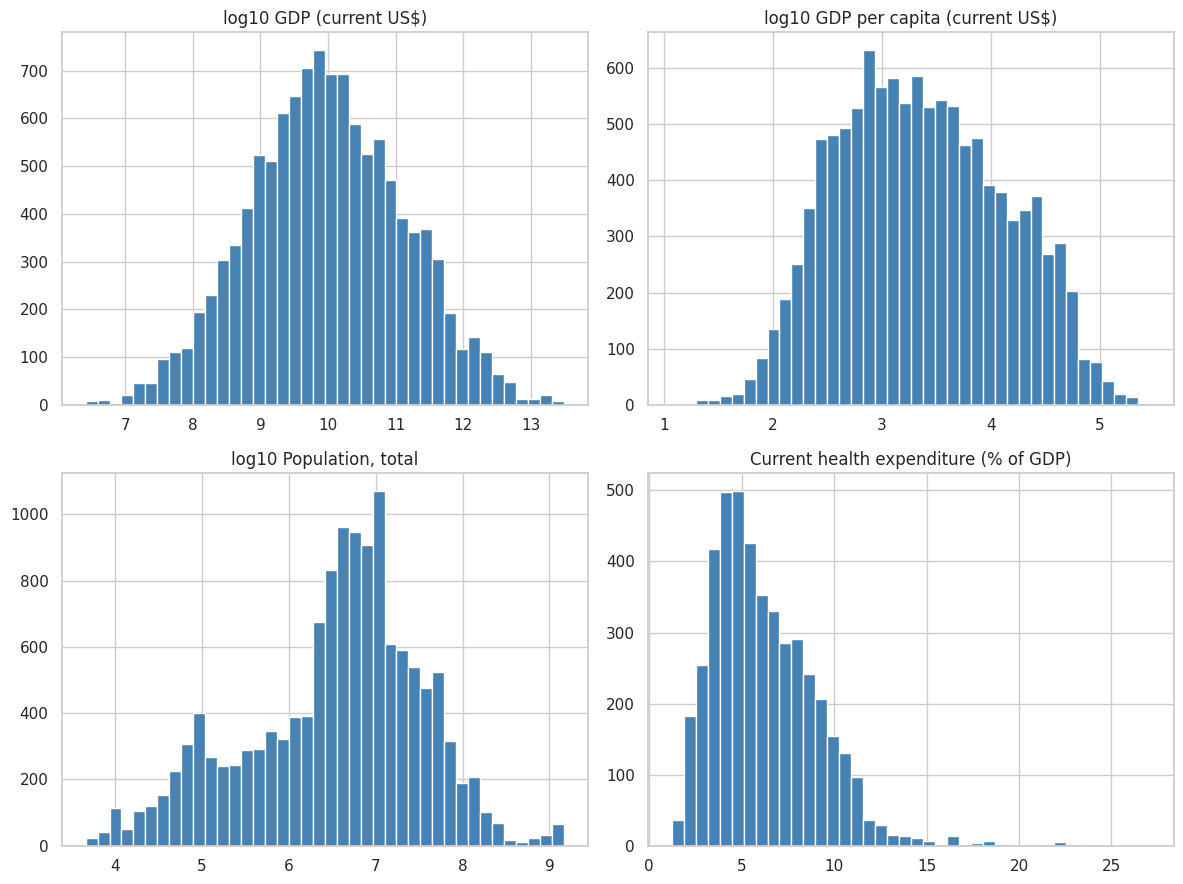

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
plots = [
    ("GDP (current US$)", True),
    ("GDP per capita (current US$)", True),
    ("Population, total", True),
    ("Current health expenditure (% of GDP)", False),
]
for ax, (col, use_log) in zip(axes.ravel(), plots):
    if col not in ECON_COLS:
        ax.set_title(col)
        ax.text(0.5, 0.5, "Indicator removed by coverage filter", ha="center", transform=ax.transAxes)
        continue
    s = data[col].dropna()
    if use_log:
        s = np.log10(s[s > 0])
        ax.set_title("log10 " + col)
    else:
        ax.set_title(col)
    ax.hist(s, bins=40, color="steelblue", edgecolor="white")
plt.tight_layout()
plt.show()


Complete-case rows (1990-2016): 2082


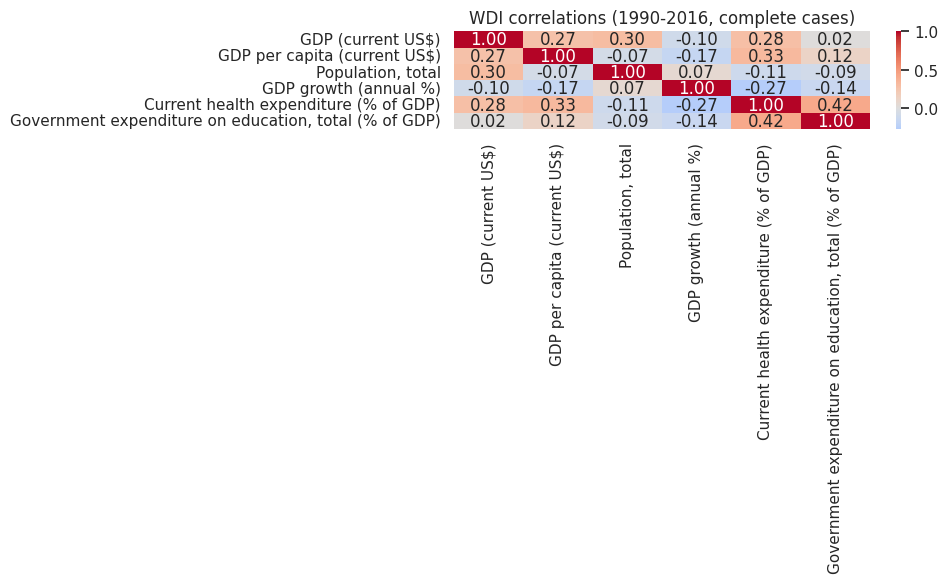

In [30]:
KEY = [
    "GDP (current US$)",
    "GDP per capita (current US$)",
    "Population, total",
    "GDP growth (annual %)",
    "Current health expenditure (% of GDP)",
    "Government expenditure on education, total (% of GDP)",
]
KEY = [c for c in KEY if c in data.columns]
sub = data[data["year"].between(1990, 2016)][KEY].dropna()
print("Complete-case rows (1990-2016):", len(sub))
if len(sub) > 50:
    sns.heatmap(sub.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("WDI correlations (1990-2016, complete cases)")
    plt.tight_layout()
    plt.show()


## 5. Olympics data overview


In [ ]:
print("Olympic years:", olympics["year"].min(), "to", olympics["year"].max())
print("Unique years:", olympics["year"].nunique())
print("Countries:", olympics["olympic_code"].nunique())
print("Rows with medals > 0:", (olympics["total"] > 0).sum(), f"({(olympics['total'] > 0).mean() * 100:.1f}%)")
display(olympics[["total", "athlete_count", "event_entries"]].describe())


In [31]:
by_year = olympics.groupby("year").agg(
    countries=("olympic_code", "nunique"),
    athletes=("athlete_count", "sum"),
    medals=("total", "sum"),
)
display(by_year.tail(10))


Olympic years: 1960 to 2016
Unique years: 21
Countries: 217
Rows with medals > 0: 1059 (39.0%)


,total,athlete_count,event_entries
count,"2,715.0000","2,715.0000","2,715.0000"
mean,5.0114,54.1860,76.5448
std,15.1090,94.1999,133.9684
min,0.0000,1.0000,1.0000
25%,0.0000,5.0000,6.0000
50%,0.0000,14.0000,19.0000
75%,3.0000,56.0000,76.0000
max,217.0000,693.0000,968.0000


,countries,athletes,medals
year,,,
1998,71,"2,172.0000",205.0000
2000,197,"10,586.0000",922.0000
2002,76,"2,393.0000",234.0000
2004,199,"10,466.0000",921.0000
2006,78,"2,493.0000",252.0000
2008,202,"10,816.0000",954.0000
2010,81,"2,535.0000",258.0000
2012,202,"10,461.0000",958.0000
2014,87,"2,741.0000",295.0000


In [ ]:
top = (
    olympics.groupby(["country", "olympic_code"])[["gold", "silver", "bronze", "total"]]
    .sum()
    .sort_values("total", ascending=False)
    .head(15)
)
display(top)


,,gold,silver,bronze,total
country,olympic_code,,,,
United States,USA,662.0000,547.0000,485.0000,"1,694.0000"
Soviet Union,URS,407.0000,314.0000,298.0000,"1,019.0000"
Germany,DEU,225.0000,232.0000,224.0000,681.0000
China,CHN,237.0000,189.0000,174.0000,600.0000
Russia,RUS,192.0000,163.0000,184.0000,539.0000
East Germany,GDR,192.0000,165.0000,162.0000,519.0000
Italy,ITA,161.0000,143.0000,178.0000,482.0000
France,FRA,132.0000,145.0000,192.0000,469.0000
Great Britain,GBR,141.0000,147.0000,168.0000,456.0000


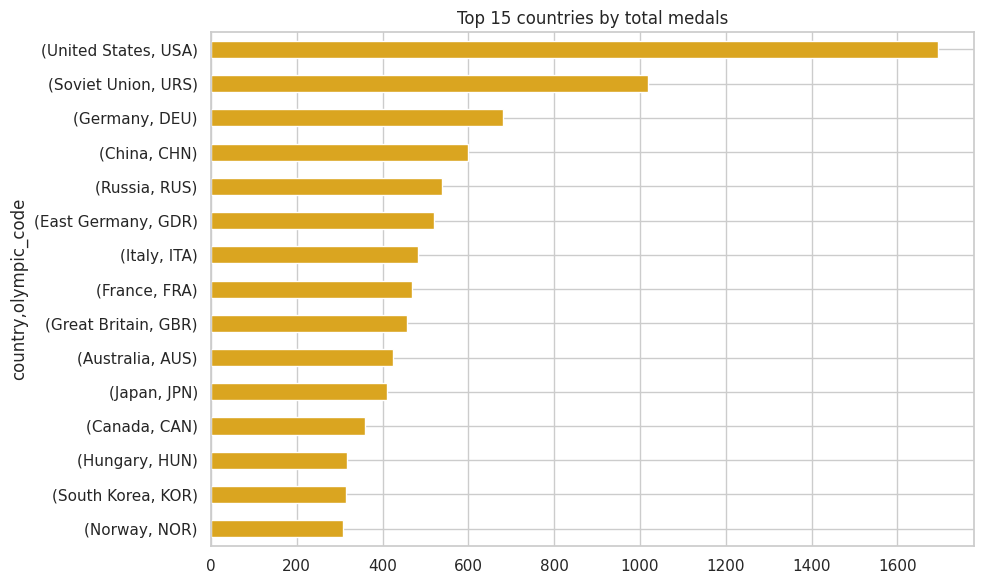

In [32]:
top["total"].plot.barh(color="goldenrod", title="Top 15 countries by total medals")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


## 6. Team size vs medals


In [ ]:
recent = olympics[olympics["year"] >= 1990]
plt.scatter(recent["athlete_count"], recent["total"], alpha=0.35, s=25)
plt.xlabel("Athletes sent")
plt.ylabel("Total medals")
plt.title("Athlete count vs medals (1990+)")
plt.tight_layout()
plt.show()


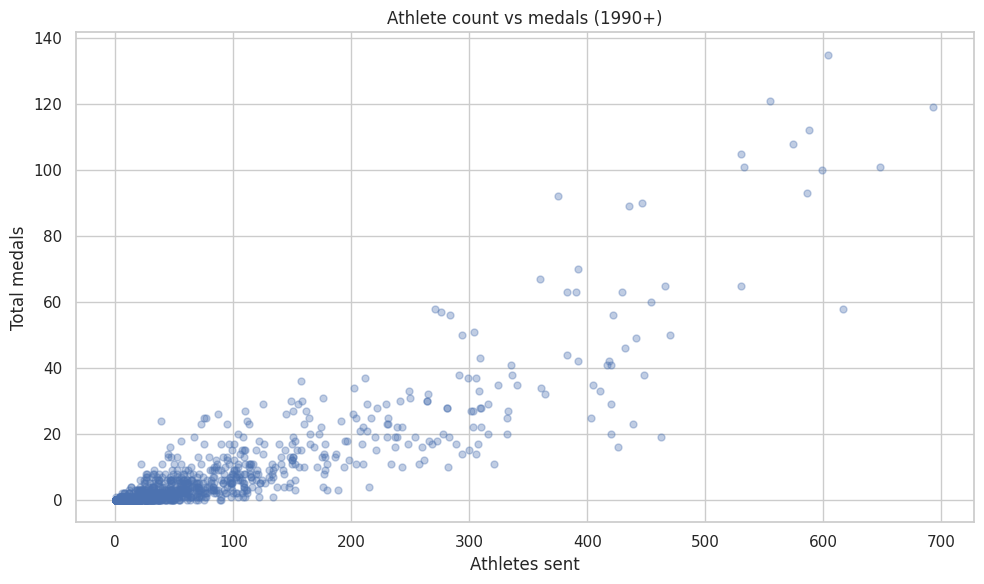

Pearson r: 0.8866282751755898
Spearman rho: 0.810045101341853


In [33]:
print("Pearson r:", recent["athlete_count"].corr(recent["total"]))
print("Spearman rho:", recent["athlete_count"].corr(recent["total"], method="spearman"))


## 7. WDI and Olympics in the merged file

Use Olympic observations directly from the supplied merge. Do not rejoin or discard rows without WDI values. Report coverage rather than treating an absent economic observation as zero.


## 8. Economics vs medals (1990-2016 panel)


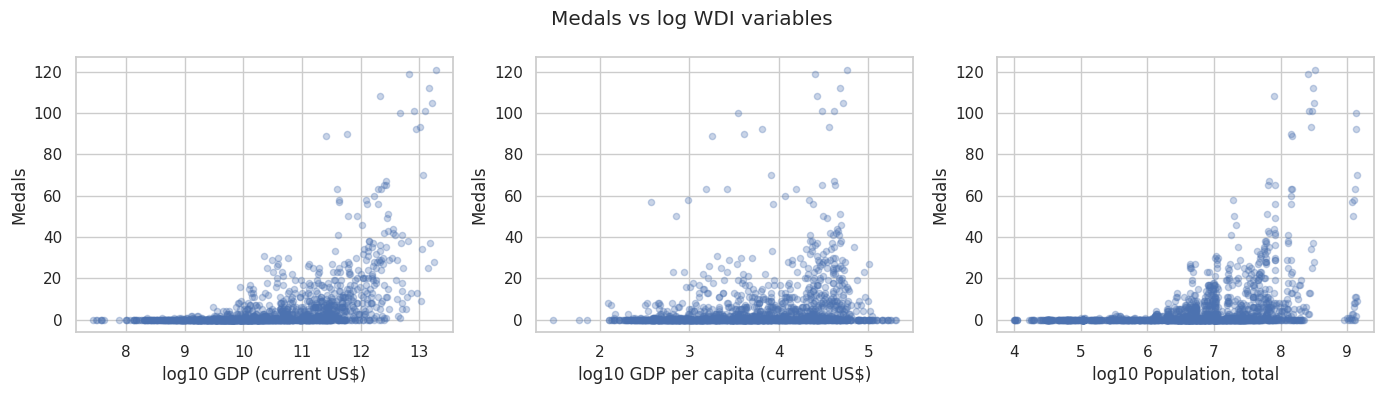

In [34]:
m = panel.copy()
for col in ["GDP (current US$)", "GDP per capita (current US$)", "Population, total"]:
    values = m[col] if col in ECON_COLS else pd.Series(np.nan, index=m.index)
    m["log_" + col] = np.log10(values.where(values > 0))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(
    axes,
    [
        "log_GDP (current US$)",
        "log_GDP per capita (current US$)",
        "log_Population, total",
    ],
):
    ax.scatter(m[col], m["total"], alpha=0.3, s=20)
    ax.set_xlabel(col.replace("log_", "log10 "))
    ax.set_ylabel("Medals")
plt.suptitle("Medals vs log WDI variables")
plt.tight_layout()
plt.show()


## 9. Stakeholder metrics (2016 snapshot)


In [ ]:
snap = m[m["year"] == 2016].copy()
snap = snap.dropna(subset=["log_GDP (current US$)", "total"])
snap["GDP (current US$)"] = 10 ** snap["log_GDP (current US$)"]
snap["log_gdp"] = np.log10(snap["GDP (current US$)"])
snap["medals_per_log_gdp"] = snap["total"] / snap["log_gdp"]

display(
    snap[snap["total"] > 0]
    .nlargest(10, "medals_per_log_gdp")[
        ["country", "athlete_count", "total", "GDP (current US$)", "medals_per_log_gdp"]
    ]
)


In [35]:
if len(snap) < 2 or snap["log_gdp"].nunique() < 2:
    print("Insufficient complete observations for the GDP baseline.")
else:
    coefs = np.polyfit(snap["log_gdp"], snap["total"], 1)
    snap["expected"] = np.polyval(coefs, snap["log_gdp"])
    snap["residual"] = snap["total"] - snap["expected"]
    display(snap.nlargest(8, "residual")[["country", "total", "expected", "residual"]])
    display(snap.nsmallest(8, "residual")[["country", "total", "expected", "residual"]])


,country,athlete_count,total,GDP (current US$),medals_per_log_gdp
12662,United States,555.0000,121.0000,"18,804,900,000,000.0352",9.1154
4412,Great Britain,360.0000,67.0000,"2,706,810,000,000.0054",5.3891
2366,China,392.0000,70.0000,"11,455,999,999,999.9902",5.3603
10286,Russia,284.0000,56.0000,"1,276,789,999,999.9990",4.6258
4214,France,392.0000,42.0000,"2,470,410,000,000.0034",3.3891
3290,Germany,418.0000,42.0000,"3,536,790,000,000.0015",3.3470
6194,Japan,335.0000,41.0000,"5,110,359,999,999.9990",3.2262
716,Australia,420.0000,29.0000,"1,211,589,999,999.9993",2.4000
5996,Italy,309.0000,28.0000,"1,887,109,999,999.9968",2.2809
2168,Canada,310.0000,22.0000,"1,528,000,000,000.0027",1.8056


,country,total,expected,residual
12662,United States,121.0000,24.7386,96.2614
4412,Great Britain,67.0000,18.7218,48.2782
2366,China,70.0000,23.2002,46.7998
10286,Russia,56.0000,16.3893,39.6107
4214,France,42.0000,18.4382,23.5618
3290,Germany,42.0000,19.5520,22.4480
6194,Japan,41.0000,20.6945,20.3055
12332,Tuvalu,0.0000,-15.7033,15.7033


,country,total,expected,residual
5600,India,2.0000,18.2093,-16.2093
10418,Saudi Arabia,0.0000,14.4758,-14.4758
5534,Indonesia,3.0000,15.4119,-12.4119
5204,Hong Kong,0.0000,12.1023,-12.1023
9362,Pakistan,0.0000,12.0316,-12.0316
8834,Nigeria,1.0000,12.8225,-11.8225
782,Austria,1.0000,12.7372,-11.7372
386,United Arab Emirates,1.0000,12.6414,-11.6414


## 10. Feature screening for modeling

The 50% missingness screen below is a **diagnostic only** for the 1990–2016 Olympic subset. It does not drop additional columns or rows. Any modeling imputation or feature selection should later be fitted using training data only.


In [36]:
miss_panel = panel[ECON_COLS].isna().mean().sort_values()
well_covered = miss_panel[miss_panel <= 0.5]
review = miss_panel[miss_panel > 0.5]
print("Retained indicators with <=50% panel missingness:", len(well_covered))
print("Retained indicators to review (>50% panel missingness):", len(review))
display((review * 100).to_frame("pct_missing"))
print("Full cleaned dataset remains:", data.shape)
print("Olympic analysis panel:", panel.shape)


Retained indicators with <=50% panel missingness: 39
Retained indicators to review (>50% panel missingness): 15


,pct_missing
Import value index (2015 = 100),55.3180
Export value index (2015 = 100),55.3180
Research and development expenditure (% of GDP),57.6206
Gini index,60.8553
"Educational attainment, at least completed upper secondary, population 25+, total (%) (cumulative)",63.9254
"Central government debt, total (% of GDP)",74.7807
"CPIA transparency, accountability, and corruption in the public sector rating (1=low to 6=high)",85.2522
CPIA trade rating (1=low to 6=high),85.2522
CPIA property rights and rule-based governance rating (1=low to 6=high),85.2522
CPIA equity of public resource use rating (1=low to 6=high),85.2522


Full cleaned dataset remains: (13584, 66)
Olympic analysis panel: (1824, 66)


## 11. Summary and next steps

1. The supplied merged dataset is the starting point; no Olympic/WDI join is rebuilt.
2. Only WDI indicators below 10% coverage across the entire file are removed. All other columns and every row remain in `data`.
3. `olympics` contains Olympic observations; `panel` restricts these to the existing 1990–2016 analysis window. Missing medals remain missing.
4. Review team size, economic distributions, correlations, and the 2016 GDP baseline above before drawing conclusions. The baseline residuals and medals per log GDP are descriptive metrics.
5. Missingness varies across indicators and countries. Fit any imputation on the training split, and use held-out Olympic years to assess future prediction.
6. Next steps: compare a medal/no-medal classifier and medal-count regression, and decide whether athlete count will be available at prediction time.


## Part 2: Group-Based Exploratory Data Analysis


## 12. Comparing Olympic Success Metrics


In [ ]:
matched = olympics.dropna(subset=["total", "athlete_count"])

country_stats = (
    matched.groupby(["country", "olympic_code"])[["total", "athlete_count"]]
    .sum()
    .rename(columns={
        "total": "medals",
        "athlete_count": "athlete_participations"
    })
)

country_stats = country_stats[
    country_stats["athlete_participations"] > 0
].copy()

country_stats["medals_per_athlete"] = (
    country_stats["medals"] / country_stats["athlete_participations"]
)

top15 = (
    country_stats
    .sort_values(
        ["medals_per_athlete", "medals"],
        ascending=[False, False]
    )
    .head(15)
    .reset_index()
)

display(top15)


,country,olympic_code,medals,athlete_participations,medals_per_athlete
0,Soviet Union,URS,"1,019.0000","3,309.0000",0.3079
1,East Germany,GDR,519.0000,"1,715.0000",0.3026
2,Unified Team,EUN,135.0000,604.0000,0.2235
3,United States,USA,"1,694.0000","8,946.0000",0.1894
4,Ethiopia,ETH,54.0000,301.0000,0.1794
5,China,CHN,600.0000,"3,520.0000",0.1705
6,Azerbaijan,AZE,42.0000,257.0000,0.1634
7,Russia,RUS,539.0000,"3,386.0000",0.1592
8,Kenya,KEN,103.0000,673.0000,0.1530
9,Norway,NOR,307.0000,"2,028.0000",0.1514


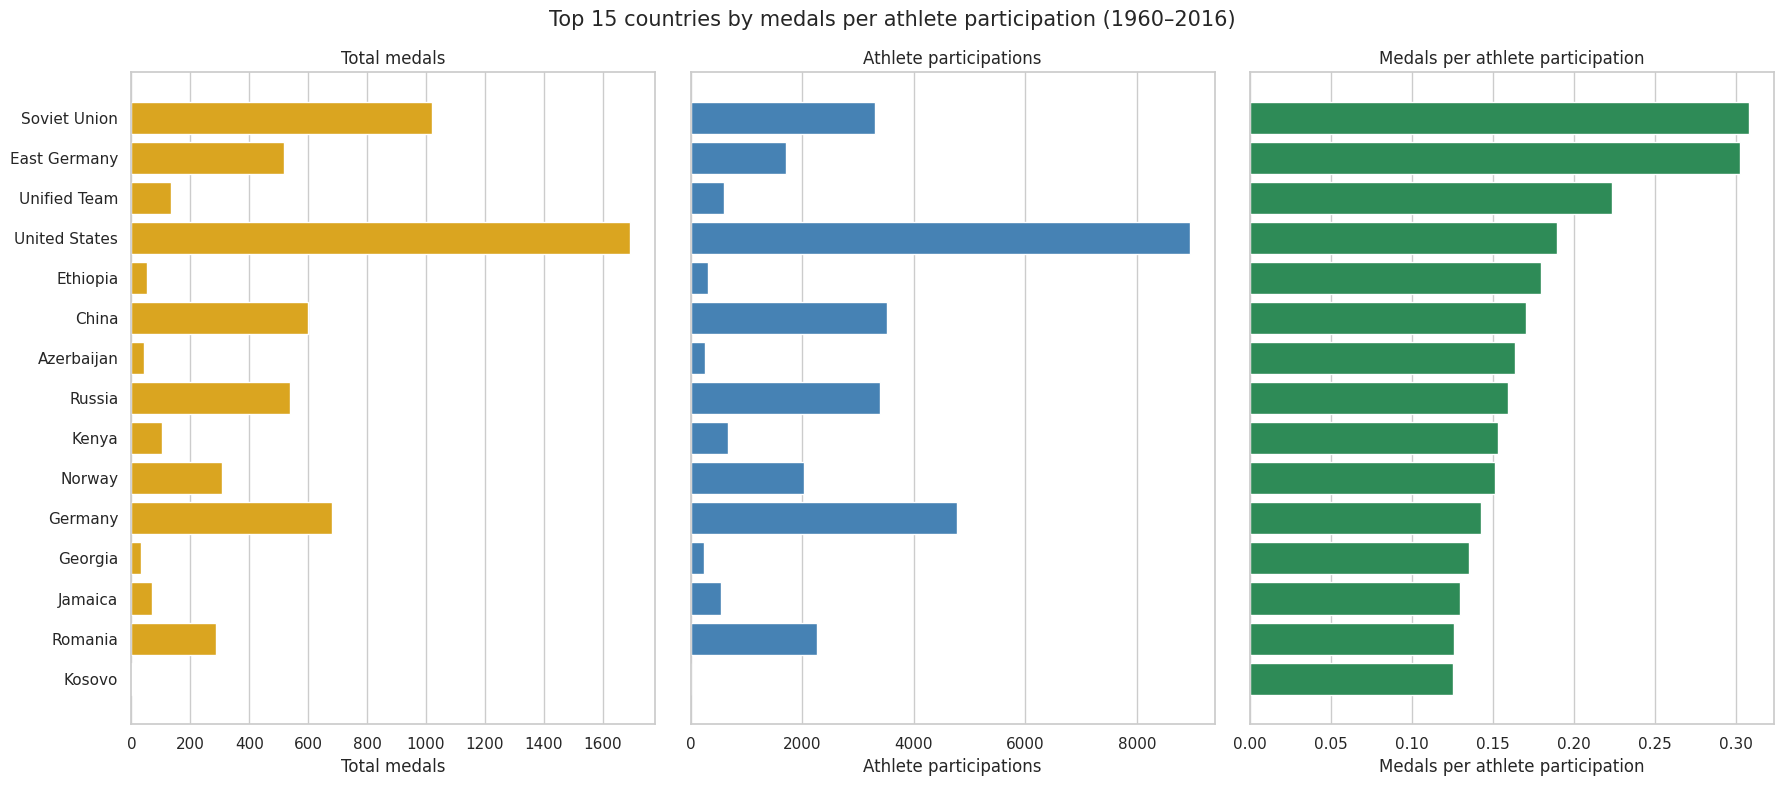

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(18, 8), sharey=True)

plots = [
    ("medals", "Total medals", "goldenrod"),
    ("athlete_participations", "Athlete participations", "steelblue"),
    ("medals_per_athlete", "Medals per athlete participation", "seagreen"),
]

for ax, (column, title, color) in zip(axes, plots):
    ax.barh(top15["country"], top15[column], color=color)
    ax.set_title(title)
    ax.set_xlabel(title)
    ax.grid(axis="y", visible=False)

axes[0].invert_yaxis()

fig.suptitle(
    "Top 15 countries by medals per athlete participation "
    f"({matched['year'].min():.0f}–{matched['year'].max():.0f})",
    fontsize=15
)
plt.tight_layout()
plt.show()


## 13. Selecting Economic Indicator Years


In [42]:
TARGET_YEAR = 2016

variables = {
    "Population, total": "population_year",
    "GDP per capita (current US$)": "gdp_per_capita_year"
}

eligible = data[
    data["wdi_code"].notna() & (data["year"] <= TARGET_YEAR)
].copy()

country_2016 = (
    eligible.sort_values("year")
    .groupby("wdi_code")[["Country"]]
    .last()
)

for column, year_column in variables.items():
    values = eligible[["wdi_code", "year", column]].copy()
    values[column] = pd.to_numeric(values[column], errors="coerce")

    latest = (
        values
        .dropna(subset=[column])
        .loc[lambda df: df[column] > 0]
        .sort_values("year")
        .drop_duplicates("wdi_code", keep="last")
        .set_index("wdi_code")
        .rename(columns={"year": year_column})
    )

    country_2016 = country_2016.join(
        latest[[column, year_column]]
    )

for column, year_column in variables.items():
    print(f"\n{column}")
    print("Using 2016:", country_2016[year_column].eq(2016).sum())
    print("Using earlier years:", country_2016[year_column].lt(2016).sum())
    print("No available data:", country_2016[column].isna().sum())

    display(
        country_2016[year_column]
        .value_counts()
        .sort_index(ascending=False)
        .rename_axis("source_year")
        .to_frame("countries")
    )



Population, total
Using 2016: 205
Using earlier years: 0
No available data: 0


,countries
source_year,
2016,205



GDP per capita (current US$)
Using 2016: 201
Using earlier years: 2
No available data: 2


,countries
source_year,
"2,016.0000",201
"2,015.0000",1
"2,011.0000",1


## 14. Grouping Countries by Population and GDP per Capita


In [ ]:
grouped_countries = country_2016.copy()

population_labels = [
    "Under 1M", "1–under 15M", "15–under 50M",
    "50M+"
]

gdp_labels = [
    "Under $2.5K", "$2.5K–under $15K", "$15K–under $30K",
    "$30K+"
]

grouped_countries["population_group"] = pd.cut(
    grouped_countries["Population, total"],

    bins=[0, 1e6, 15e6, 50e6, np.inf],
    labels=population_labels,
    right=False
)

grouped_countries["gdp_per_capita_group"] = pd.cut(
    grouped_countries["GDP per capita (current US$)"],

    bins=[0, 2500, 15000, 40000, np.inf],
    labels=gdp_labels,
    right=False
)

valid = grouped_countries.dropna(
    subset=["population_group", "gdp_per_capita_group"]
)

counts = pd.crosstab(
    valid["population_group"],
    valid["gdp_per_capita_group"],
    dropna=False
).reindex(
    index=population_labels,
    columns=gdp_labels,
    fill_value=0
)

if valid.empty:
    raise ValueError("No countries have both population and GDP per capita.")

percentages = counts / len(valid) * 100

annotations = counts.copy().astype(str)

for row in counts.index:
    for col in counts.columns:
        annotations.loc[row, col] = (
            f"{counts.loc[row, col]}\n"
            f"({percentages.loc[row, col]:.1f}%)"
        )

plt.figure(figsize=(12, 7))
sns.heatmap(
    counts,
    annot=annotations,
    fmt="",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "Number of countries"}
)

plt.xlabel("GDP per capita group")
plt.ylabel("Population group")
plt.title(
    "Country groups by population and GDP per capita\n"
    "2016 values with earlier-year fallback"
)
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


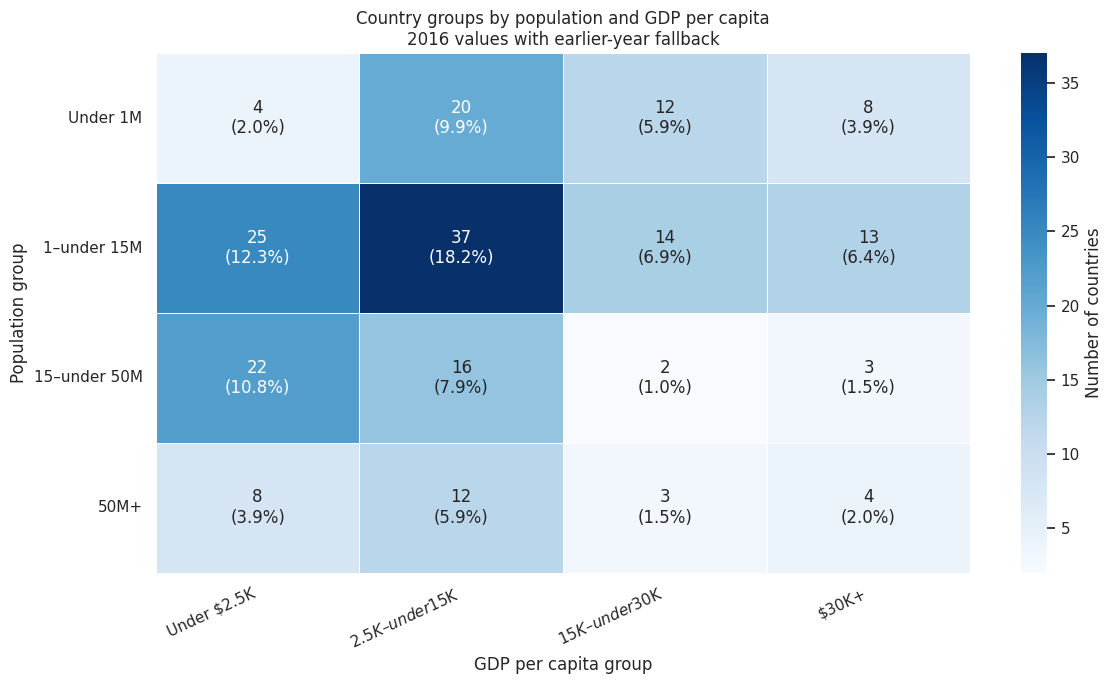

In [49]:
group_members = (
    valid.reset_index()
    .assign(
        country_name=lambda df: df["Country"].fillna(df["wdi_code"])
    )
    .groupby(
        ["population_group", "gdp_per_capita_group"],
        observed=True
    )
    .agg(
        country_count=("wdi_code", "size"),
        countries=("country_name", lambda names: ", ".join(sorted(names)))
    )
    .reset_index()
)


### Refining Population and GDP Groups


In [45]:
group_names = (
    group_members[
        ["population_group", "gdp_per_capita_group"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

group_names["group_name"] = [
    f"Group {i + 1}" for i in range(len(group_names))
]

country_groups = (
    valid.reset_index()
    .merge(
        group_names,
        on=["population_group", "gdp_per_capita_group"],
        how="left",
        validate="many_to_one"
    )
    .rename(columns={
        "Country": "country",
        "Population, total": "population",
        "GDP per capita (current US$)": "gdp_per_capita"
    })
)

country_groups["country"] = (
    country_groups["country"].fillna(country_groups["wdi_code"])
)

country_groups = (
    country_groups[
        [
            "group_name",
            "wdi_code",
            "country",
            "population_group",
            "gdp_per_capita_group",
            "population",
            "gdp_per_capita",
            "population_year",
            "gdp_per_capita_year"
        ]
    ]
    .sort_values(
        ["population_group", "gdp_per_capita_group", "country"]
    )
    .reset_index(drop=True)
)
display(country_groups)


,group_name,wdi_code,country,population_group,gdp_per_capita_group,population,gdp_per_capita,population_year,gdp_per_capita_year
0,Group 1,COM,Comoros,Under 1M,Under $2K,"741,741.0000","1,365.4840",2016,"2,016.0000"
1,Group 1,KIR,Kiribati,Under 1M,Under $2K,"118,478.0000","1,742.6680",2016,"2,016.0000"
2,Group 1,STP,Sao Tome and Principe,Under 1M,Under $2K,"203,689.0000","1,434.8702",2016,"2,016.0000"
3,Group 2,BLZ,Belize,Under 1M,$2K–under $10K,"364,705.0000","6,140.8671",2016,"2,016.0000"
4,Group 2,BTN,Bhutan,Under 1M,$2K–under $10K,"747,866.0000","3,152.3091",2016,"2,016.0000"
...,...,...,...,...,...,...,...,...,...
198,Group 16,ITA,Italy,50M+,$30K+,"60,115,223.0000","31,391.5693",2016,"2,016.0000"
199,Group 16,JPN,Japan,50M+,$30K+,"127,076,000.0000","40,214.9689",2016,"2,016.0000"
200,Group 16,KOR,"Korea, Rep.",50M+,$30K+,"51,217,803.0000","30,832.0628",2016,"2,016.0000"
201,Group 16,GBR,United Kingdom,50M+,$30K+,"65,606,000.0000","41,258.5374",2016,"2,016.0000"


## 15. Economic Data Coverage by Group


In [ ]:
economic_factors = ECON_COLS

economics_2016 = data.loc[
    data["year"].eq(2016) & data["wdi_code"].notna(),
    ["wdi_code"] + economic_factors
].copy()

group_economics = country_groups[
    ["wdi_code", "country", "group_name"]
].merge(
    economics_2016,
    on="wdi_code",
    how="left",
    validate="one_to_one"
)

included_by_group = (
    group_economics[economic_factors]
    .notna()
    .groupby(group_economics["group_name"])
    .mean()
    .mul(100)
    .reindex(group_order)
)

included_by_group.index.name = "group_name"

group_summary = pd.DataFrame({
    "countries": (
        group_economics.groupby("group_name")
        .size()
        .reindex(group_order)
    ),
    "overall_included_pct": included_by_group.mean(axis=1)
})

levels = ["Very low", "Low", "Middle", "High"]

group_numbers = (
    group_economics["group_name"]
    .str.extract(r"(\d+)$")[0]
    .astype(int)
)

if not group_numbers.between(1, 16).all():
    raise ValueError("This mapping requires group numbers from 1 to 16.")

chart_data = group_economics.copy()

chart_data["population_category"] = (
    ((group_numbers - 1) // 4).map(dict(enumerate(levels)))
)

chart_data["gdp_category"] = (
    ((group_numbers - 1) % 4).map(dict(enumerate(levels)))
)

chart_data["included_pct"] = (
    chart_data[economic_factors].notna().mean(axis=1) * 100
)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
summaries = {}

for ax, category, title in [
    (axes[0], "population_category", "Population"),
    (axes[1], "gdp_category", "GDP per capita")
]:
    summary = (
        chart_data.groupby(category)
        .agg(
            countries=("wdi_code", "nunique"),
            included_pct=("included_pct", "mean")
        )
        .reindex(levels)
    )

    summary["countries"] = summary["countries"].fillna(0).astype(int)
    summaries[title] = summary

    bars = ax.bar(
        levels,
        summary["included_pct"],
        color="steelblue" if title == "Population" else "seagreen"
    )

    ax.bar_label(
        bars,
        labels=[
            f"{pct:.1f}%\n{count} countries"
            if pd.notna(pct) else "No countries"
            for pct, count in zip(
                summary["included_pct"], summary["countries"]
            )
        ],
        padding=5
    )

    ax.set_title(f"Economic data included by {title.lower()}")
    ax.set_ylabel("Data included (%)")
    ax.set_ylim(0, 115)
    ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()


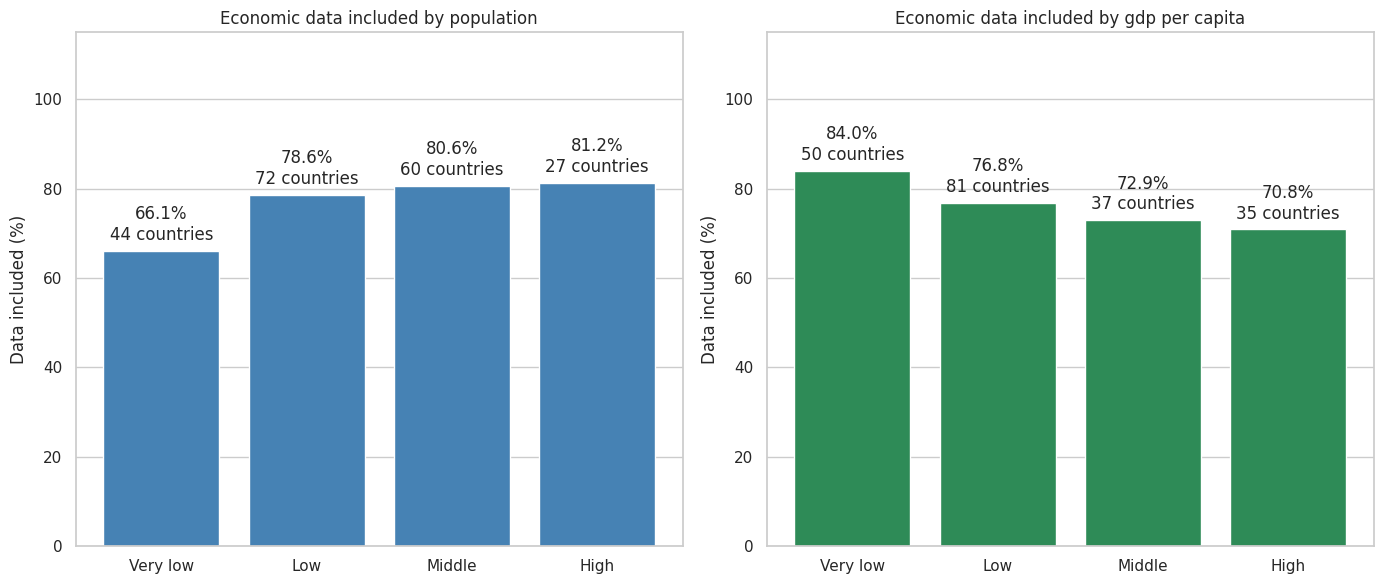

countries  included_pct
grouped_by     category                         
Population     Very low         44       66.1000
               Low              72       78.6000
               Middle           60       80.6000
               High             27       81.2000
GDP per capita Very low         50       84.0000
               Low              81       76.8000
               Middle           37       72.9000
               High             35       70.8000

In [52]:
display(
    pd.concat(
        summaries,
        names=["grouped_by", "category"]
    ).round(1)
)


## 16. Comparing Medal Performance Across Groups


In [ ]:
results_2016 = data.loc[
    data["year"].eq(2016) & data["wdi_code"].notna(),
    ["wdi_code", "total", "athlete_count"]
].copy()

medal_data = chart_data[
    [
        "wdi_code", "country", "group_name",
        "population_category", "gdp_category"
    ]
].merge(
    results_2016,
    on="wdi_code",
    how="left",
    validate="one_to_one"
)

medal_data = medal_data.dropna(subset=["total", "athlete_count"])
medal_data = medal_data[medal_data["athlete_count"] > 0].copy()

medal_data["medals_per_participation"] = (
    medal_data["total"] / medal_data["athlete_count"]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, category, title in [
    (axes[0], "population_category", "Population"),
    (axes[1], "gdp_category", "GDP per capita")
]:
    summary = (
        medal_data.groupby(category)
        .agg(
            average_ratio=("medals_per_participation", "mean"),
            countries=("wdi_code", "nunique")
        )
        .reindex(levels)
    )

    bars = ax.bar(
        levels,
        summary["average_ratio"],
        color="steelblue" if title == "Population" else "seagreen"
    )

    ax.bar_label(
        bars,
        labels=[
            f"{ratio:.3f}\n{int(count)} countries"
            if pd.notna(ratio) else "No data"
            for ratio, count in zip(
                summary["average_ratio"], summary["countries"]
            )
        ],
        padding=4
    )

    ax.set_title(f"Average medals per participation by {title.lower()}")
    ax.set_ylabel("Average country medals / athletes")
    ax.margins(y=0.25)
    ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()


In [ ]:
group_order_16 = [f"Group {i}" for i in range(1, 17)]

group_medals = (
    medal_data.groupby("group_name")
    .agg(
        average_medals_per_participation=(
            "medals_per_participation", "mean"
        ),
        countries=("wdi_code", "nunique"),
        total_medals=("total", "sum"),
        total_participations=("athlete_count", "sum")
    )
    .reindex(group_order_16)
)

group_medals["countries"] = (
    group_medals["countries"].fillna(0).astype(int)
)


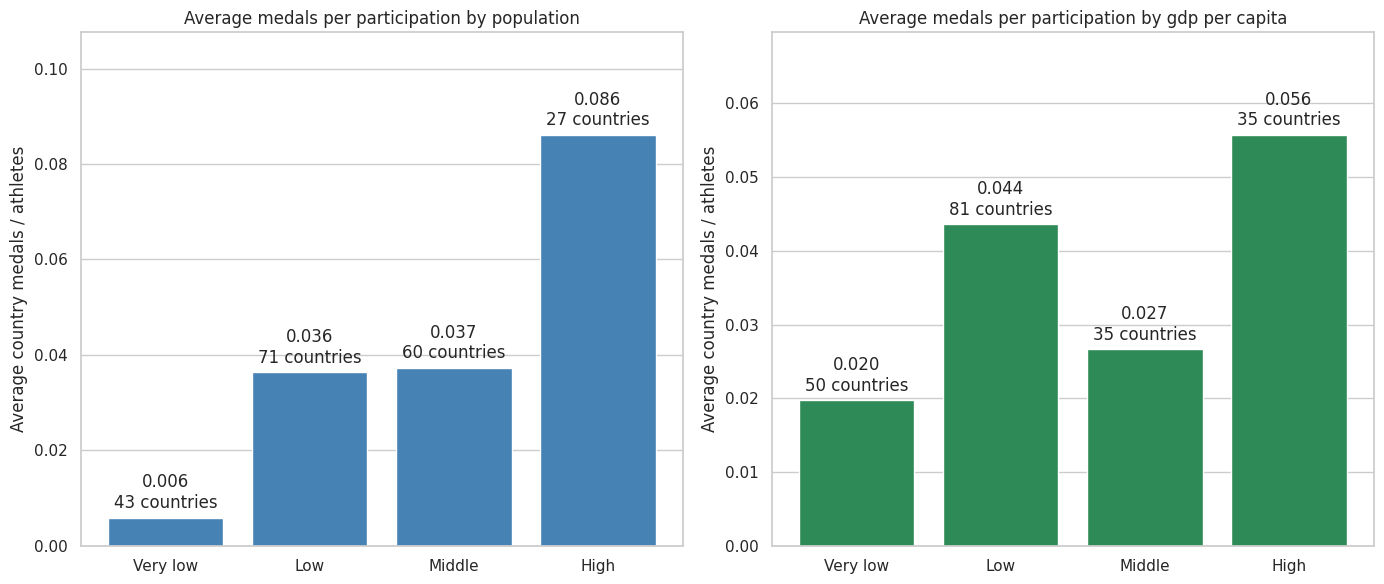

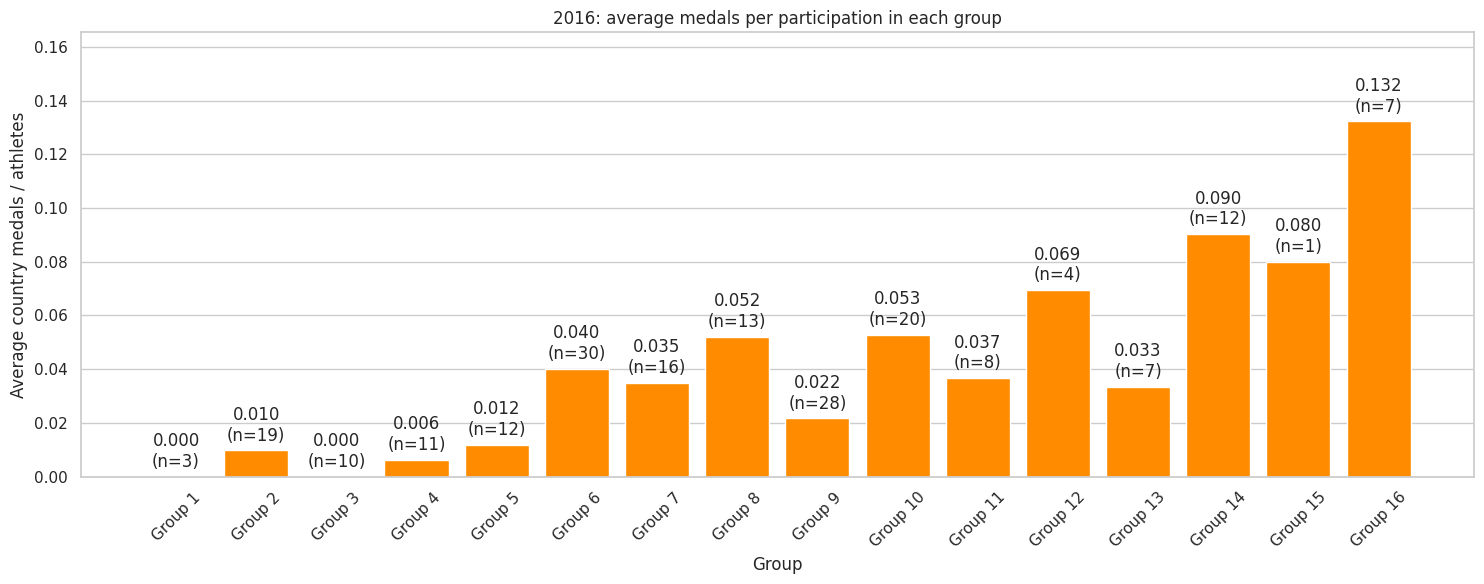

In [54]:
fig, ax = plt.subplots(figsize=(15, 6))

bars = ax.bar(
    group_medals.index,
    group_medals["average_medals_per_participation"],
    color="darkorange"
)

ax.bar_label(
    bars,
    labels=[
        f"{ratio:.3f}\n(n={count})"
        if pd.notna(ratio) else "No data"
        for ratio, count in zip(
            group_medals["average_medals_per_participation"],
            group_medals["countries"]
        )
    ],
    padding=4
)

ax.set_title("2016: average medals per participation in each group")
ax.set_ylabel("Average country medals / athletes")
ax.set_xlabel("Group")
ax.tick_params(axis="x", rotation=45)
ax.margins(y=0.25)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()


## 17. Country-Level Differences Within Groups


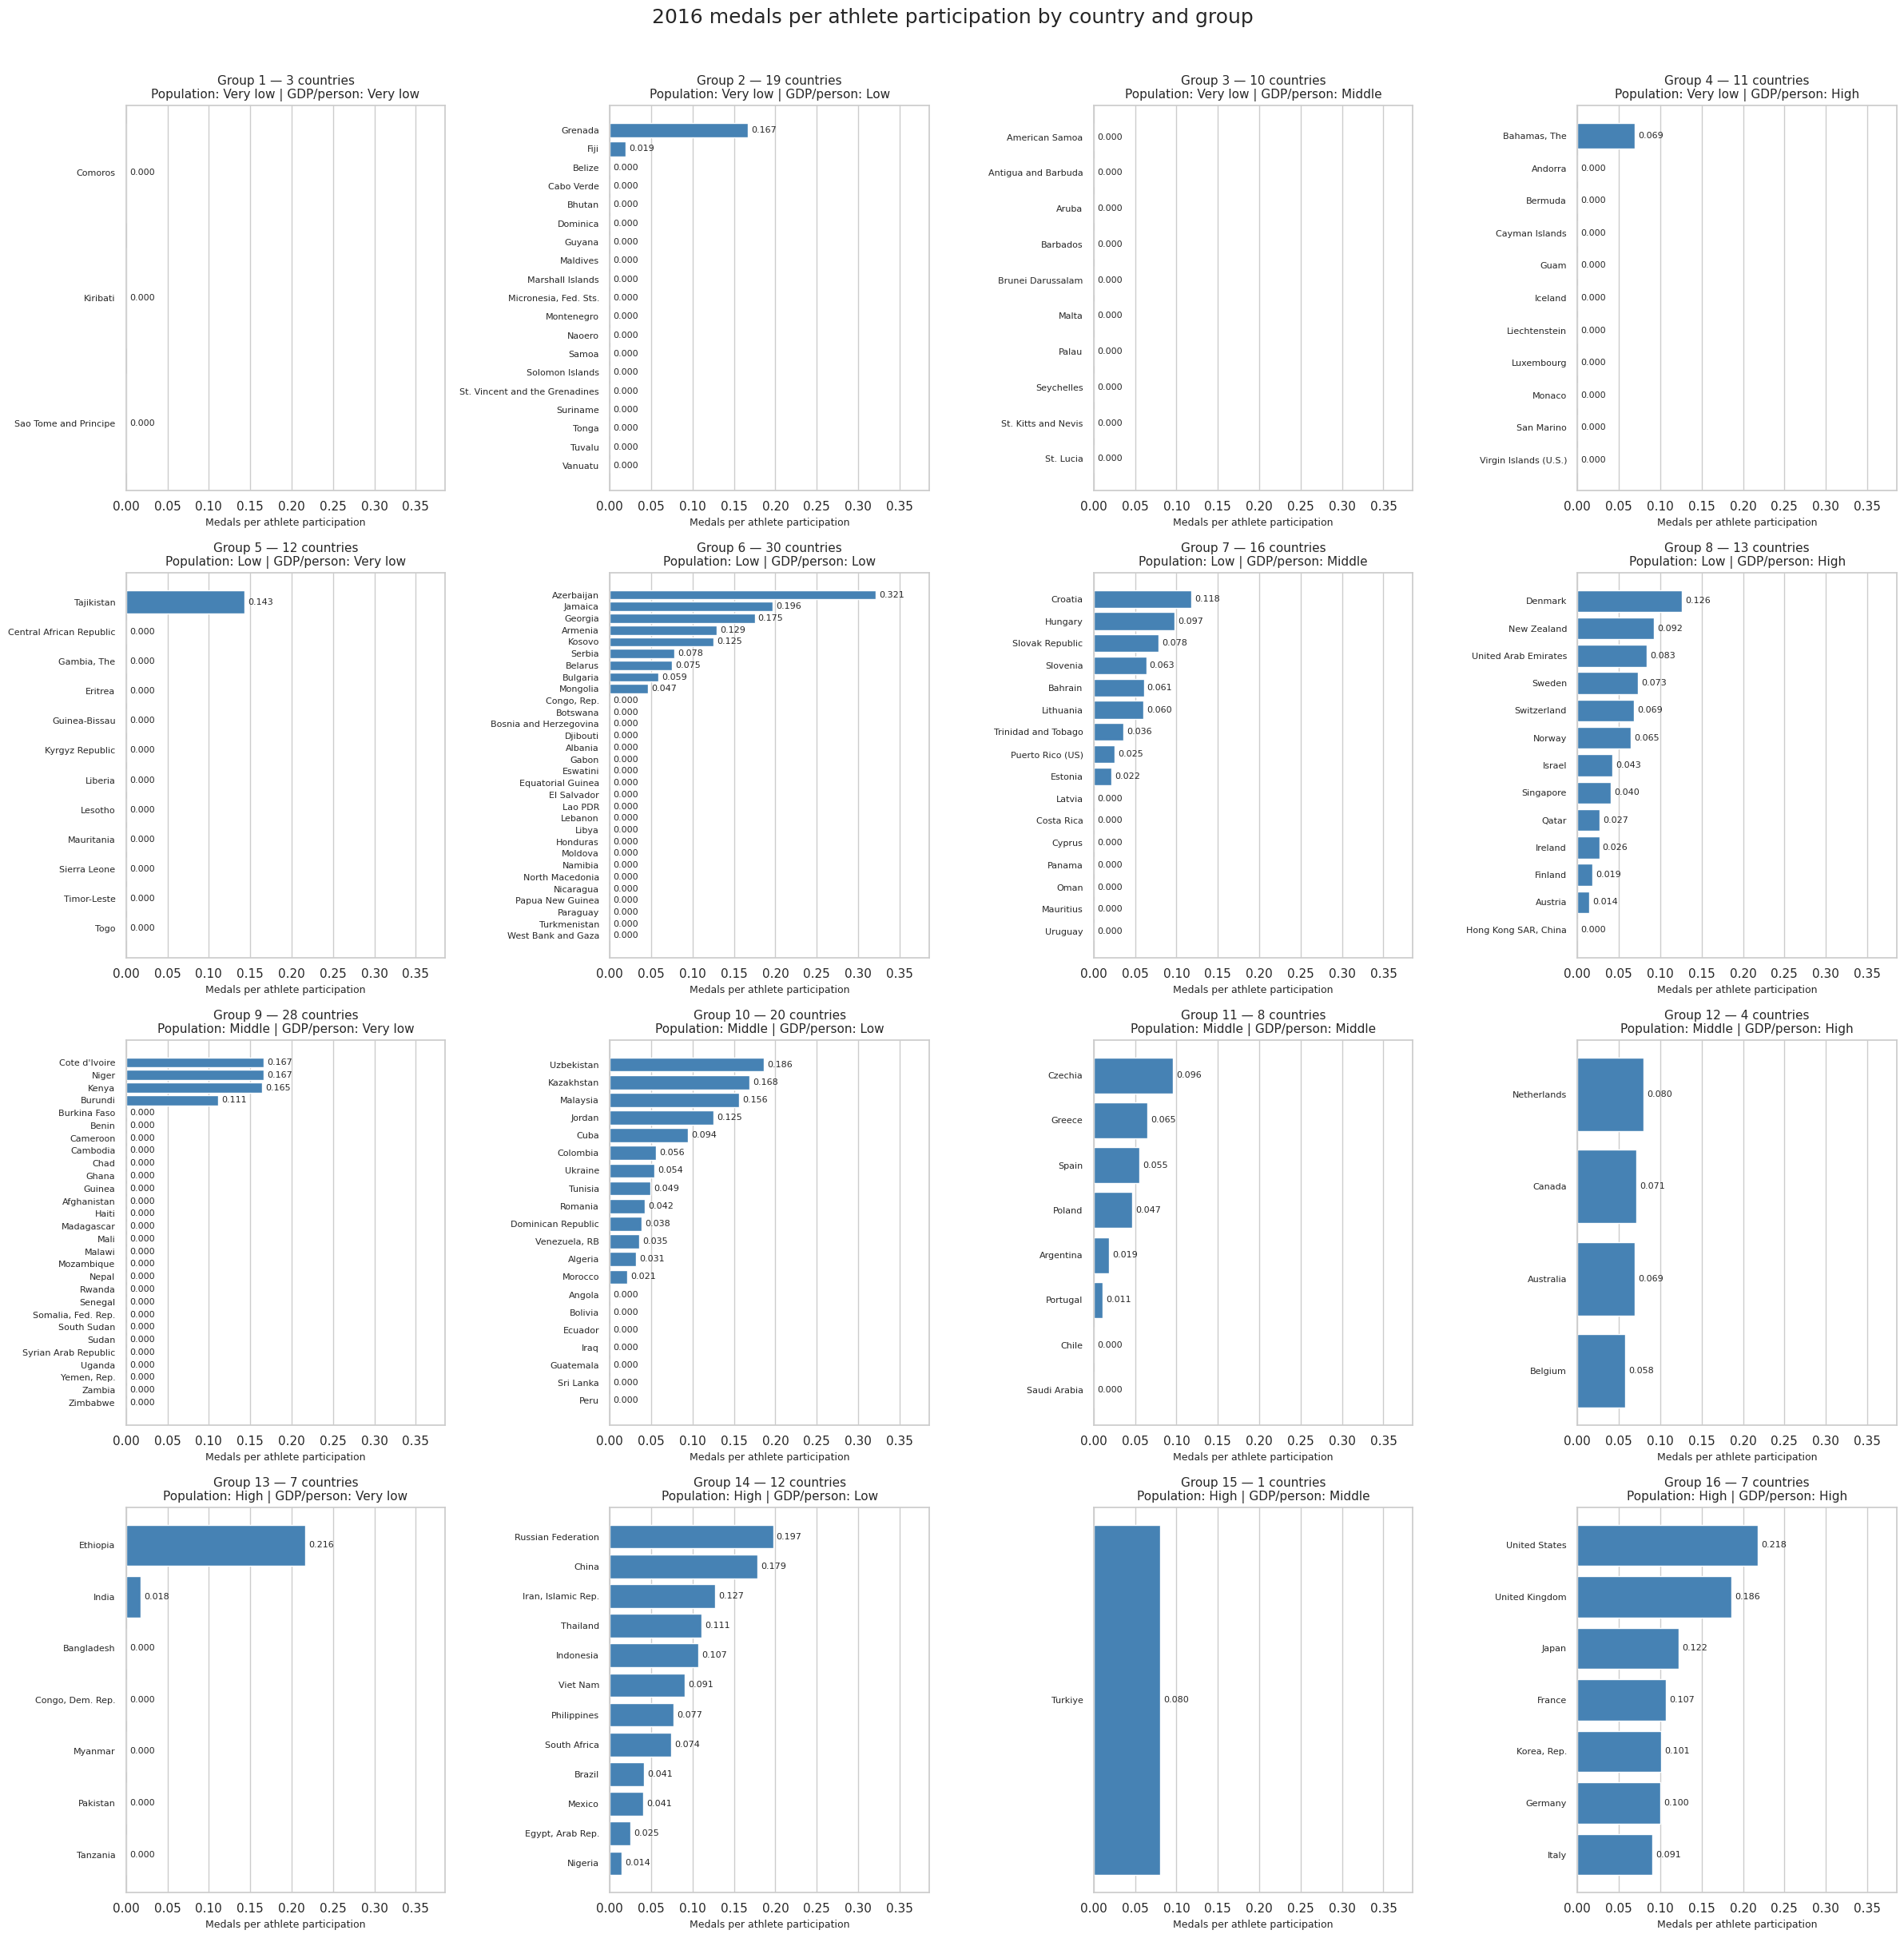

In [55]:
fig, axes = plt.subplots(4, 4, figsize=(24, 24), sharex=True)

max_ratio = medal_data["medals_per_participation"].max()
x_limit = max_ratio * 1.2 if pd.notna(max_ratio) and max_ratio > 0 else 1

for group_number, ax in enumerate(axes.ravel(), start=1):
    group_name = f"Group {group_number}"

    subset = (
        medal_data[medal_data["group_name"].eq(group_name)]
        .sort_values("medals_per_participation", ascending=False)
        .copy()
    )

    population_level = levels[(group_number - 1) // 4]
    gdp_level = levels[(group_number - 1) % 4]

    ax.set_title(
        f"{group_name} — {len(subset)} countries\n"
        f"Population: {population_level} | GDP/person: {gdp_level}",
        fontsize=11
    )

    if subset.empty:
        ax.text(
            0.5, 0.5, "No available Olympic data",
            ha="center", va="center",
            transform=ax.transAxes
        )
    else:
        positions = np.arange(len(subset))
        labels = subset["country"].fillna(subset["wdi_code"])

        bars = ax.barh(
            positions,
            subset["medals_per_participation"],
            color="steelblue"
        )

        ax.set_yticks(positions)
        ax.set_yticklabels(labels, fontsize=8)
        ax.invert_yaxis()

        ax.bar_label(
            bars,
            labels=[
                f"{value:.3f}"
                for value in subset["medals_per_participation"]
            ],
            padding=3,
            fontsize=8
        )

    ax.set_xlim(0, x_limit)
    ax.set_xlabel("Medals per athlete participation", fontsize=9)
    ax.tick_params(axis="x", labelbottom=True)
    ax.grid(axis="y", visible=False)

fig.suptitle(
    "2016 medals per athlete participation by country and group",
    fontsize=18,
    y=1.01
)

plt.tight_layout()
plt.show()


## 18. Assigning Ungrouped Countries


## 19. Machine Learning With and Without Groups
